<a name="toc" id="toc"></a>
# Convolution Neural Network (CNN) - Flower Classification

We train a CNN from scratch to tell five kinds of flowers apart (daisy, dandelion, roses,
sunflowers, tulips), and then we open the trained network up to see what each layer has learnt to
look for.

All images live in the `images/` folder next to this notebook - `images/Training` and
`images/Testing`, one sub-folder per flower - so every path below is relative and the notebook runs
as-is on any machine.

---

## Table of Contents

| # | Section | What happens there |
|---|---------|--------------------|
| 1 | [Dataset and libraries](#sec1) | Where the images come from, and the imports we need |
| 2 | [Image augmentation](#sec2) | Create endless variations of the training images on the fly |
| 3 | [Loading the images from disk](#sec3) | Read the folders in batches, folder name becomes the label |
| 4 | [Building the CNN](#sec4) | Three Conv+Pool blocks, then Flatten and two Dense layers |
| 5 | [Compiling the model](#sec5) | Pick the optimizer, the loss and the metric |
| 6 | [Training the model](#sec6) | Run the training loop over the generators |
| 6A | [Train for 10 epochs and save the model](#sec6a) | Train properly once, save it to a file, load it back (runs here or in Colab) |
| 7 | [Looking inside the network](#sec7) | Plot what every conv/pool layer produced for one image |
| 8 | [How the visualisation works](#sec8) | Take the helper apart, one line at a time |

<a id="sec1"></a>
## 1. Dataset and libraries

**What:** the source of the flower images, and the Keras pieces we build the network from.

**Why these imports:** `Sequential` stacks layers in a straight line, `Conv2D` and `MaxPooling2D` do
the feature extraction, `Flatten` turns feature maps into a vector and `Dense` does the actual
classification at the end.

[&#8593; Back to TOC](#toc)

In [ ]:
# What: Original source of the flower dataset used in this notebook.
# Why : The same 5-class flower images are already kept locally in the "images" folder that sits
#       next to this notebook, so every cell below runs with a relative path and no download.
#Dataset link:
#https://drive.google.com/drive/folders/1ESsfpI6sYTtHoUv8ihI0AJSOVgij6xfq?usp=sharing

In [ ]:
# Mount Google Drive (on Colab)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# What: Importing the libraries for the layers of CNN
# Why : Sequential lets us stack layers one after the other, Conv2D/MaxPooling2D do the feature
#       extraction, Flatten turns feature maps into a vector and Dense does the classification.
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense

In [ ]:
# What: Importing the library for image handling/preprocessing
# Why : gives the helpers that read an image from the disk and turn it into a numeric array
from tensorflow.keras.preprocessing import image

<a id="sec2"></a>
## 2. Image augmentation

**What:** an `ImageDataGenerator` that rotates, shifts, shears, zooms and flips each training
image slightly, differently, every single epoch.

**Why:** we only have ~2,700 training images, which is little for a network with 1.6 million weights.
Augmentation means the model almost never sees the exact same picture twice, so it learns what a
rose *is* instead of memorising particular rose photographs. Note test data is never augmented, otherwise the score we read would not be an honest one.

[&#8593; Back to TOC](#toc)

In [ ]:
# Image Augumentation
# create few more images by stretching, zooming, shrinking, rotating, flipping the available images
# This will make the model to learn very generically about the data
# Why : we only have ~2700 training images - augmentation shows the model a slightly different
#       version of every image in every epoch, which reduces overfitting for free
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1/255.,           # Normalizes pixel values from [0, 255] to the [0, 1] range
    rotation_range=45,        # Randomly rotates images clockwise or counterclockwise up to 45 degrees
    width_shift_range=0.2,    # Randomly shifts images horizontally by up to 20% of the total width
    height_shift_range=0.2,   # Randomly shifts images vertically by up to 20% of the total height
    shear_range=0.2,          # Applies a random shear angle (slanting effect) up to 20%
    zoom_range=0.2,           # Randomly zooms inside the image by a factor between 80% and 120%
    horizontal_flip=True,     # Randomly flips images horizontally (left to right)
    fill_mode='reflect'       # how to fill the empty corners created by shift/rotation
)

**Height Shift**

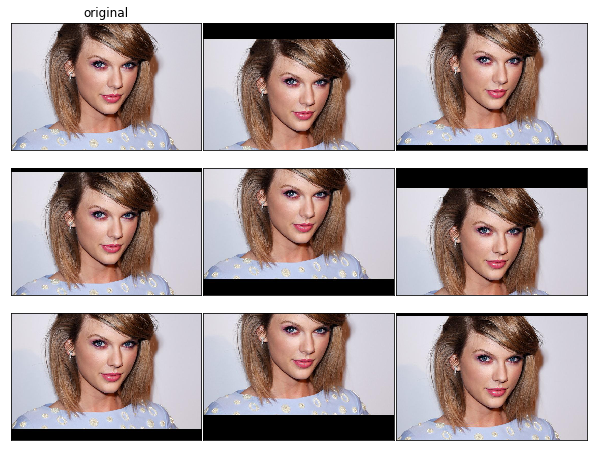

In [ ]:
test_datagen=ImageDataGenerator(rescale=1/255.) # We dont change the test data
# only scaling is enough for test data
# Why : test data must stay untouched so that the score we read is an honest one. The 1/255
#       rescaling is NOT augmentation - it is the same preprocessing the model was trained with.

<a id="sec3"></a>
## 3. Loading the images from disk

**What:** `flow_from_directory` walks `images/Training` and `images/Testing`, resizes every
picture to 128x128 and hands them to the model in batches of 128.

**Why a generator and not one big array:** 3,670 images at 128x128x3 would sit in RAM all at once.
A generator reads and augments each batch only when the model asks for it. The sub-folder names
(daisy, dandelion, roses, sunflowers, tulips) automatically become the five class labels.

[&#8593; Back to TOC](#toc)

**3 class categorical cross entropy**

$$
\text{Loss} = - \sum_{i=1}^{3} y_i \log(\hat{y}_i) = - (y_1 \log(\hat{y}_1) + y_2 \log(\hat{y}_2) + y_3 \log(\hat{y}_3))
$$


In [ ]:
# Laod the images from the train and test folders by resizing it for 128x128
#Image augumentaion defined above will be performed for each batch of images
# class mode is "categorical" for multiclass problem ("binary" for binomial problem)
# Why : the path is relative ("images" folder lives next to this notebook), so the notebook runs
#       on any machine without editing paths. Each sub-folder name becomes one class label.
training_set=train_datagen.flow_from_directory('/content/drive/MyDrive/GL/S2_CNN/images/Training',
                                              target_size=(128,128),
                                              batch_size=128,
                                              class_mode='categorical')

# Total of 2736 images corresponds to 5 differnt classses are loaded in to this notebook
                                                   #from the training folder (harddrive)

Found 2736 images belonging to 5 classes.


In [ ]:
# What: same thing for the test images, but using the plain (non-augmenting) generator
test_set=test_datagen.flow_from_directory('/content/drive/MyDrive/GL/S2_CNN/images/Testing',
                                              target_size=(128,128),
                                              batch_size=128,
                                              class_mode='categorical')

# Total of 934 images corresponds to 5 differnt classses are loaded in to this notebook
                                                   #from the testing folder (harddrive)

Found 934 images belonging to 5 classes.


<a id="sec4"></a>
## 4. Building the CNN

**What:** three Conv+Pool blocks with 16, 32 and 64 filters, then `Flatten`, a 128-unit hidden
layer and a 5-unit softmax output.

**Why this shape:** each Conv layer learns filters that fire on a pattern - early ones on edges and
colour blobs, later ones on petal and leaf textures. Each Pool layer halves the resolution, so later
filters cover a larger part of the flower while staying cheap. Filter counts grow as the maps shrink,
because deeper layers need to describe more varied patterns.

[&#8593; Back to TOC](#toc)

In [ ]:
classifier = Sequential() # Sequentialy we are going to add the layers in this network

#Define the convolution layer with 16 kernals each of size 3x3
# This layer will accept the images of size 128x128x3
# Activation function for this layer is ReLU
# Why ReLU: it keeps the positive filter responses and zeroes the rest, which is what makes the
#           network non-linear and lets it learn edges -> textures -> shapes
#
# Note: on THIS layer every argument below 'activation' is written out at its DEFAULT value, purely
#       so we can see what Keras assumes when we stay silent. Deleting all four lines gives the
#       exact same layer. The later layers leave them implicit, as usual.
classifier.add(Conv2D(16, (3, 3), input_shape = (128, 128, 3), activation = 'relu',
                      strides = (1, 1),         # default. How far the kernel jumps between two
                                                # positions: 1 pixel right, 1 pixel down. strides=(2,2)
                                                # would skip every other position and halve the output.
                      padding = 'valid',        # default. 'valid' = no padding, the kernel stays fully
                                                # inside the image, so 128 -> 126. 'same' would pad with
                                                # a border of zeros and keep the output at 128x128.
                      use_bias = True          # default. One bias number is added per filter, on top
                                                # of the weighted sum, before ReLU.
                      ))

#Maxpool layer generally defined at the end of each convolution layer.
#Poolsize of 2x2 will bring down the feature map(convolution layer output) size by half
# Why : fewer pixels to carry forward (cheaper) and small shifts in the object stop mattering
classifier.add(MaxPooling2D(pool_size = (2, 2),
                            strides = None,     # default. None means "use pool_size", i.e. (2,2) here,
                                                # so the 2x2 windows sit side by side and never overlap.
                            padding = 'valid')) # default. An odd leftover row/column is dropped rather
                                                # than padded - 126/2 = 63 exactly, so nothing is lost here.

# Define the second convolution and maxpool layer
# Why more filters deeper in: the maps are smaller, so we can afford more of them, and deeper
#      layers need to describe more varied patterns
# Note: same defaults as above (strides 1x1, padding 'valid'), just left implicit now
classifier.add(Conv2D(32, (3, 3), activation = 'relu'))
classifier.add(MaxPooling2D(pool_size = (2, 2)))

#Third Convolution and Maxpool Layer
classifier.add(Conv2D(64, (3, 3), activation = 'relu'))
classifier.add(MaxPooling2D(pool_size = (2, 2)))

# Flatten the feature map produced by the last convolution layer as single vector
# Why : Dense layers accept a 1D vector, not a 3D stack of feature maps
classifier.add(Flatten())

#Add the hidden layers
# Note: the two arguments below are again the defaults, shown once for Dense as well
classifier.add(Dense(units = 128,activation = 'relu',
                     use_bias = True                        # default. one bias per neuron
                      ))

# Output layer should have 5 neurons as this data is having 5 classes of flowers
#"Softmax" activation function is preferred for Multiclass problem
# Why : softmax turns the 5 raw scores into probabilities that add up to 1
classifier.add(Dense(units = 5, activation = 'softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Model summary**

**What:** the layer-by-layer table of output shapes and trainable parameters.

**Why look at it:** it shows where the model's capacity actually sits. Notice that the convolution
layers hold only a few thousand weights while the Dense layer right after `Flatten` holds well over a
million - that layer, not the convolutions, is where this model is most likely to overfit.

In [ ]:
# What: layer-by-layer table of output shapes and number of trainable parameters
# Why : quick sanity check - notice how most parameters sit in the Dense layer after Flatten
classifier.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,629,989 (6.22 MB)

 Trainable params: 1,629,989 (6.22 MB)

 Non-trainable params: 0 (0.00 B)

<a id="sec5"></a>
## 5. Compiling the model

**What:** attach the optimizer (how weights get updated), the loss (what is minimised) and the
metric we read to judge progress.

**Why these:** `adam` adapts the step size per weight so it works well untuned;
`categorical_crossentropy` matches our one-hot labels and softmax output; `accuracy` is the number a
human actually cares about.

[&#8593; Back to TOC](#toc)

In [ ]:
#compile the CNN model with 'adam' optimizer to minimize the loss (cross entropy)
# Why categorical_crossentropy: our labels are one-hot (class_mode='categorical') and we have >2 classes
# Why adam: adapts the learning rate per weight, so it works well without manual tuning
classifier.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])

<a id="sec6"></a>
## 6. Training the model

**What:** run the training loop, feeding it the training generator and scoring against the test
generator after each epoch.

**Why `steps_per_epoch`:** a generator is endless, so Keras has to be told how many batches make up
one pass over the data - 2736 images / 128 per batch = 21 updates. The epoch count is kept at 1 here
only to keep the demo quick; raise it to 20-30 for a model that actually learns, since after a single
epoch accuracy will still be close to random guessing for 5 classes.

[&#8593; Back to TOC](#toc)

In [ ]:
# Fit(Train) the model using trainset of data
# How many time the weight needs to be updated in one iteratin will be decided by steps_per_epoch
# How many iteration for which the training need to be happen will be decided by 'epochs'
# Note: fit_generator() has been removed in Keras 3 - plain fit() takes the generator directly
print('batches per epoch:', len(training_set), '| validation batches:', len(test_set))

classifier.fit(training_set,
               steps_per_epoch = len(training_set),   # 22 updates = all 2736 training images
               epochs =1,
               validation_data = test_set,
               validation_steps = len(test_set))      # 8 batches = all 934 test images

batches per epoch: 22 | validation batches: 8


KeyboardInterrupt: 

<a id="sec6a"></a>
## 6A. Save and load previously trained model or saved weights

**What:** section 6 above trained for a single epoch just to keep the notebook quick. Here the same
`classifier` is trained for **10 epochs** and written to a file, so in class the trained model can
simply be loaded instead of being retrained in front of everyone.

[&#8593; Back to TOC](#toc)

In [ ]:
# What: decide WHERE the model will be written, and print the full path before writing anything
# Why : "the file is saved" is useless information without the exact path - especially in Colab,
#       where /content is wiped the moment the runtime disconnects
import os

# What: detect whether this cell is running in Google Colab or on a local machine
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# What: the folder we save into
#   - on Colab : /content  (the runtime's working folder - TEMPORARY, gone when the runtime ends)
#   - locally  : the folder this notebook sits in
SAVE_DIR = '/content/drive/MyDrive/GL/S2_CNN' if IN_COLAB else os.getcwd()

# What: the two file names. .keras is the modern Keras 3 format, .h5 is the older one
MODEL_NAME = 's2_1_10epochs'
KERAS_PATH = os.path.join(SAVE_DIR, MODEL_NAME + '.keras')   # recommended format
H5_PATH    = os.path.join(SAVE_DIR, MODEL_NAME + '.h5')      # legacy format, still readable

print('Running in Colab :', IN_COLAB)
print('Save folder      :', SAVE_DIR)
print('Will save to     :', KERAS_PATH)
print('             and :', H5_PATH)

Running in Colab : True
Save folder      : /content/drive/MyDrive/GL/S2_CNN
Will save to     : /content/drive/MyDrive/GL/S2_CNN/s2_1_10epochs.keras
             and : /content/drive/MyDrive/GL/S2_CNN/s2_1_10epochs.h5


## Load previously trained model weights

In [ ]:
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

classifier = Sequential()
classifier.add(Conv2D(16, (3, 3), input_shape=(128, 128, 3), activation='relu'))
classifier.add(MaxPooling2D(pool_size=(2, 2)))
classifier.add(Conv2D(32, (3, 3), activation='relu'))
classifier.add(MaxPooling2D(pool_size=(2, 2)))
classifier.add(Conv2D(64, (3, 3), activation='relu'))
classifier.add(MaxPooling2D(pool_size=(2, 2)))
classifier.add(Flatten())
classifier.add(Dense(units=128, activation='relu'))
classifier.add(Dense(units=5, activation='softmax'))

classifier.load_weights('/content/drive/MyDrive/GL/S2_CNN/s2_1_10epochs.weights.h5')   # <- the portable file
classifier.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [ ]:
# # ---------------------------- TRAINING FOR 10 EPOCHS LOCALLY ----------------------------
# # What: train the same `classifier` for 10 epochs
# # Why : section 6 already ran 1 epoch, so these 10 epochs CONTINUE from those weights - the model
# #       is not reset. In a fresh Colab session this is simply the first real training run.
# # Note: steps_per_epoch = len(training_set) = 22, so each epoch is one full pass over all 2736
# #       images. See the comment in section 6 for why 2736//128 would quietly skip every 2nd epoch.
# history_10 = classifier.fit(training_set,
#                             steps_per_epoch = len(training_set),
#                             epochs = 10,
#                             validation_data = test_set,
#                             validation_steps = len(test_set))

In [ ]:
# # ---------------------------- SAVING ----------------------------
# # What: write the trained model to disk - architecture AND weights in one file
# # Why : save() stores everything needed to rebuild the model, so in class we only load_model()
# classifier.save(KERAS_PATH)    # modern format, no warning
# classifier.save(H5_PATH)       # legacy format, prints a harmless "legacy format" notice
# classifier.save_weights(os.path.join(SAVE_DIR, MODEL_NAME + '.weights.h5'))

# # What: confirm both files exist, with their absolute path and size
# # Why : a save that silently failed looks exactly like a save that worked, until class starts
# for p in (KERAS_PATH, H5_PATH):
#     print(f'{os.path.abspath(p)}   ({os.path.getsize(p)/1e6:.2f} MB)')

In [ ]:
# # What: Colab only - keep the file somewhere permanent, and/or pull it down to the laptop
# # Why : /content is deleted when the Colab runtime disconnects. Google Drive and the download are
# #       the two ways to make the model outlive the session.
# if IN_COLAB:
#     # ---- option 1: copy into Google Drive (asks you to authorise the first time) ----
#     from google.colab import drive
#     drive.mount('/content/drive')                       # What: Drive appears at /content/drive

#     DRIVE_DIR = '/content/drive/MyDrive/GL/S2_CNN'       # What: any folder you like inside MyDrive
#     os.makedirs(DRIVE_DIR, exist_ok=True)               # Why : the copy fails if the folder is missing

#     import shutil
#     drive_path = shutil.copy(KERAS_PATH, DRIVE_DIR)
#     print('Saved to Google Drive :', drive_path)

#     # ---- option 2: download straight to your own machine ----
#     from google.colab import files
#     files.download(KERAS_PATH)                          # What: browser downloads the .keras file
#     print('Download started for  :', KERAS_PATH)
# else:
#     print('Not running in Colab - the local copies above are already permanent:')
#     print('  ', os.path.abspath(KERAS_PATH))

In [ ]:
# # ---------------------------- LOADING BACK ----------------------------
# # What: load the saved file and use it, exactly as you would in class
# # Why : proves the file is complete. A model that cannot be reloaded is worse than no saved model.

# classifier = tf.keras.models.load_model(KERAS_PATH)       # <- one line rebuilds the whole model
# print('Loaded from:', os.path.abspath(KERAS_PATH))

In [ ]:
# ---------------------------- PREDICTION ----------------------------
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# What: map the generator's class numbers back to flower names, e.g. {0:'daisy', 1:'dandelion',...}
# Why : the model outputs a position, not a name
class_names = {v: k for k, v in training_set.class_indices.items()}
print('Classes    :', class_names)

# What: run one image through the reloaded model
test_path = '/content/drive/MyDrive/GL/S2_CNN/images/Training/daisy/21652746_cc379e0eea_m.jpg'
test_img  = load_img(test_path, target_size=(128, 128))
arr       = np.expand_dims(img_to_array(test_img) / 255.0, axis=0)   # scale + add batch dim
probs     = classifier.predict(arr, verbose=0)[0]

print('\nPredicted  :', class_names[int(np.argmax(probs))], f'({probs.max()*100:.1f}% confident)')
print('All probabilities:', {class_names[i]: f'{p*100:.1f}%' for i, p in enumerate(probs)})

Classes    : {0: 'daisy', 1: 'dandelion', 2: 'roses', 3: 'sunflowers', 4: 'tulips'}

Predicted  : daisy (99.0% confident)
All probabilities: {'daisy': '99.0%', 'dandelion': '0.0%', 'roses': '0.7%', 'sunflowers': '0.0%', 'tulips': '0.2%'}


<a id="sec7"></a>
## 7. Looking inside the network

**What:** push one daisy photograph through the trained model and plot the feature maps that
each convolution and pooling layer produced, using the `visualize_layer` helper kept in
`visualize_layer.py` next to this notebook.

**Why:** it turns an abstract claim into something visible - the early layers clearly keep edges and
petal outlines, while the deeper, smaller maps keep only the blobs that distinguish one flower from
another.

[&#8593; Back to TOC](#toc)

In [ ]:
#Libraries for loading image and visualising the output of each layer
# Why : visualize_layer is our own small helper (visualize_layer.py, kept next to this notebook)
#       that pushes one image through the trained model and plots what each layer produced
%matplotlib inline

import sys
folder_path = "/content/drive/MyDrive/GL/S2_CNN"
if folder_path not in sys.path:
    sys.path.append(folder_path)
# /content/drive/MyDrive/GL/S2_CNN/visualize_layer.py

from tensorflow.keras.preprocessing.image import img_to_array, load_img
import tensorflow as tf
import numpy as np
from matplotlib import pyplot as plt
from visualize_layer import visualize_layer
import warnings
warnings.filterwarnings('ignore')   # What: hide the harmless deprecation notices, keeps output clean



In [28]:
# What: pick any one image from the dataset - relative path, so it works on every machine
img_path='/content/drive/MyDrive/GL/S2_CNN/images/Training/daisy/21652746_cc379e0eea_m.jpg'

# # Why : seeing the feature maps makes the "CNN learns edges first, shapes later" idea concrete
# visualize_layer(img_path,classifier) # Function to visualize the output of each layer

<a id="sec8"></a>
## 8. How the visualisation works, step by step

**What:** the same idea as the helper, unpacked. We inspect a layer, look at its symbolic input
and output, then build a throw-away model that shares the trained weights but stops at the first
convolution layer, and plot all 16 of its feature maps.

**Why it works:** a Keras model is a graph of tensors. Asking for a new `Model` with the same input
but a different output does not retrain or copy anything - it just reads the existing graph up to
that point, so its prediction *is* that layer's output.

[&#8593; Back to TOC](#toc)

In [30]:
#input of the CNN model
# Note: in Keras 3 use .inputs (a list) - the older .input attribute is not available on a
#       Sequential model that has not been called on a symbolic tensor
classifier.inputs

[<KerasTensor shape=(None, 128, 128, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_46>]

In [ ]:
# The first layer of CNN (i.e first convolution layer)
# Why : a model is just a list of layers - classifier.layers lets us inspect them one by one
classifier.layers[0]

<Conv2D name=conv2d_3, built=True>

In [ ]:
# output of the first layer
# What: a symbolic tensor (None, 126, 126, 16) - 16 feature maps of 126x126
# Why : 128 - 3 + 1 = 126, because a 3x3 kernel with no padding loses one pixel on each side
classifier.layers[0].output

<KerasTensor shape=(None, 126, 126, 16), dtype=float32, sparse=False, ragged=False, name=keras_tensor_47>

In [32]:
#Visuale the first layer output only (16 feature maps)
# What: build a throw-away model that shares the trained weights but stops at the first conv layer
# Why : its prediction IS the first layer's output, which is exactly what we want to plot
viz_model = tf.keras.models.Model(inputs = classifier.inputs, outputs = classifier.layers[0].output)
img = load_img(img_path, target_size=(128, 128))   # What: read + resize the image
x  = img_to_array(img)                            # What: PIL image -> array (128,128,3)
print(x.shape)
x=np.expand_dims(x,0)                              # What: add batch dim -> (1,128,128,3)
x /= 255.0                                         # Why : match the 1/255 scaling used in training
feature_maps = viz_model.predict(x)

print(feature_maps.shape) # 1 image with 16 channels (feature maps), each having 126 x 126 dimension

(128, 128, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
(1, 126, 126, 16)


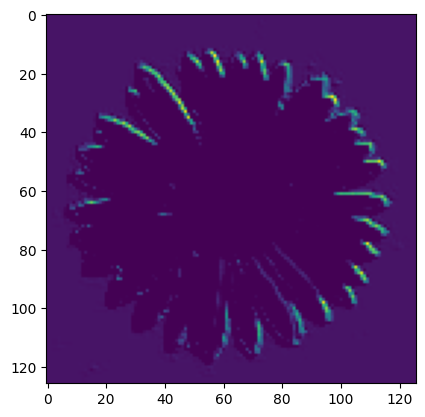

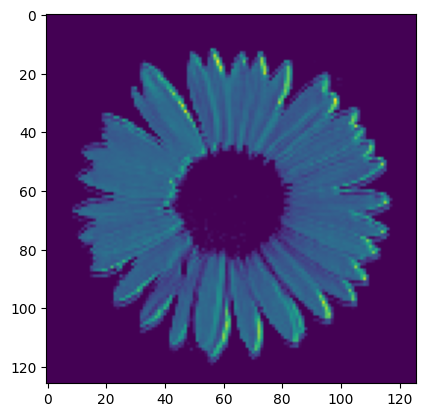

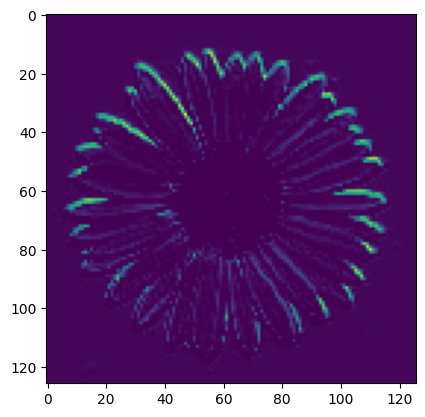

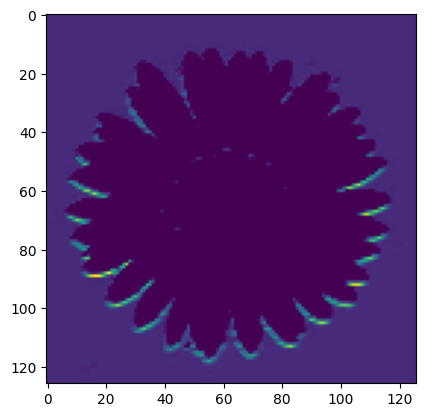

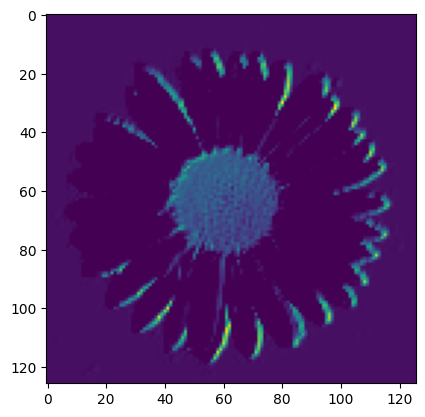

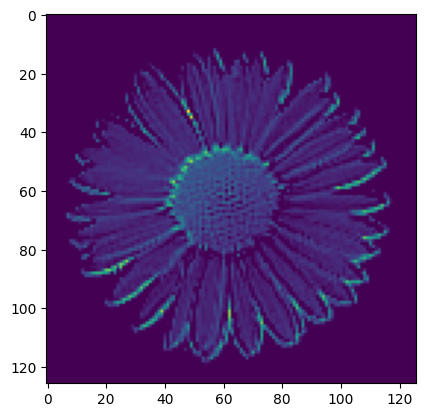

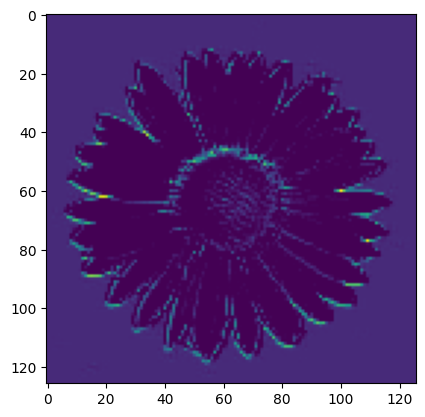

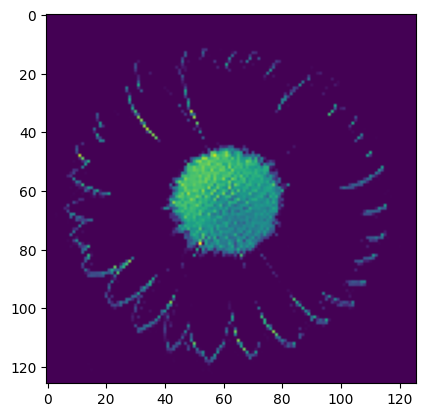

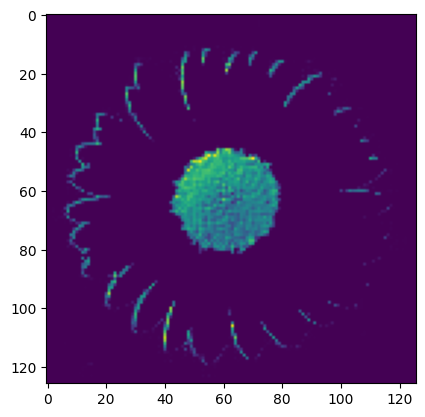

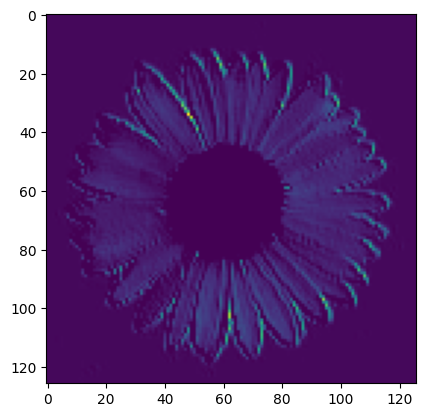

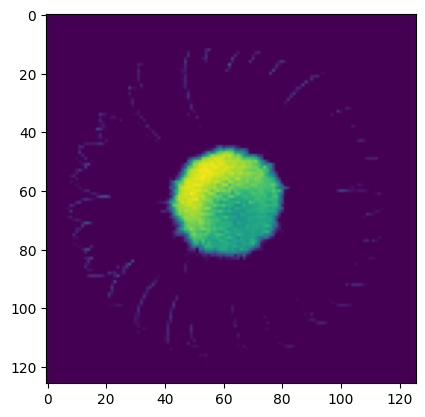

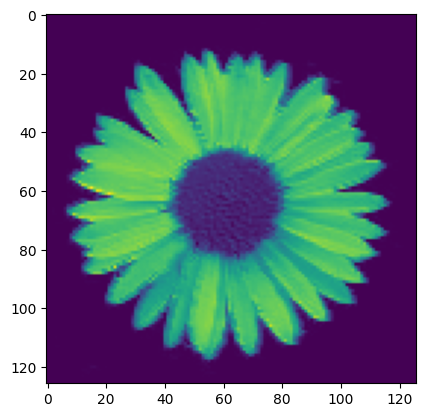

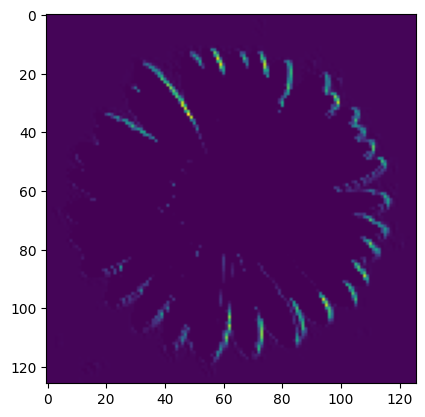

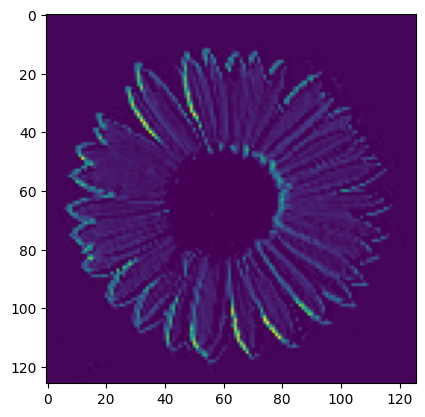

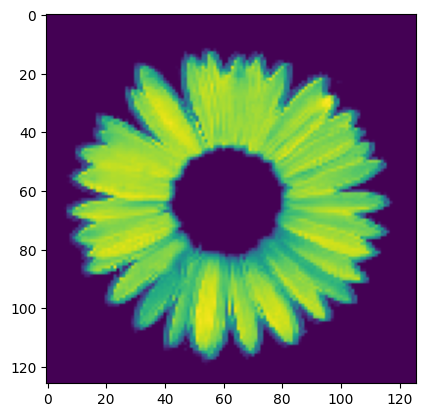

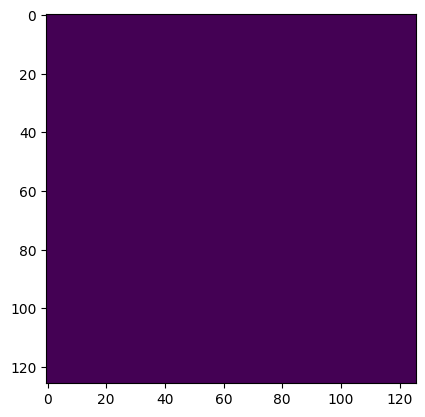

In [45]:
for i in range(0,feature_maps.shape[-1]):          # What: loop over all 16 filters
    plt.imshow(feature_maps[:,:,:,i][0])           # What: show the i-th feature map
    plt.show()